# AI-Driven Multi-Modal Framework for Smart Contract Vulnerability Detection
## Dedicated Vyper GNN Pipeline (Structural Analysis Path)

### Research Scope & System Architecture
This notebook implements the dedicated, language-specific Graph Neural Network (GNN) pipeline for **Vyper smart contracts** within the larger Multi-Modal Vulnerability Detection Framework.

1. **Dedicated Per-Language Pipeline**:
   - Independent structural training and evaluation pipeline strictly for Vyper (EVM Pythonic domain).
   - Generates and exports a 32-dimensional latent structural embedding tensor ($H_{struct} \in \mathbb{R}^{32}$) for late multimodal fusion with Member 02's semantic embedding (CodeBERT/LLM).
2. **Exact 12-Dimensional Feature Deconstruction Schema**:
   - Quantitative continuous scale ($[0.0, 1.0]$):
     - **F0** (Normalized Length): $\min(\text{Lines} / 60.0, 1.0)$
     - **F1** (Branching Complexity): $\min(\text{Decision Density} / 5.0, 1.0)$
   - Qualitative Security Semantics (Binary flags $\{0.0, 1.0\}$):
     - **F2** (Functional Scope): 1.0 if def, @external, @internal, @deploy, @view, @pure, interface; else 0.0
     - **F3** (Entry Visibility): 1.0 if @external, @payable, @deploy, public(); else 0.0
     - **F4** (Critical Execution Hooks): 1.0 if raw_call, send, selfdestruct; else 0.0
     - **F5** (Invariant Guards): 1.0 if assert, raise, @nonreentrant, nonreentrant; else 0.0
     - **F6** (Arithmetic Channels): 1.0 if unsafe_add, unsafe_sub, unsafe_mul, unsafe_div; else 0.0
     - **F7** (State Mutations): 1.0 if storage assignment '=' (excluding ==, !=, <=, >=); else 0.0
   - Qualitative Domain & Topology Markers ($\{0.0, 1.0\}$):
     - **F8** (EVM Domain Flag): 1.0 for Vyper
     - **F9** (Sealevel Domain Flag): 0.0
     - **F10** (Pythonic EVM Domain Flag): 1.0 for Vyper
     - **F11** (Context Root Hub Flag): 1.0 for the root/hub node, 0.0 for standard functional execution blocks
3. **Multi-Level Graph Synthesis**:
   - **Single_File Contracts**: Individual contracts parsed into execution blocks, sequential edges, and star edges to Node 0 (Root Hub).
   - **Folder_Wise Projects**: Multi-contract project repositories unified into a single graph with a global Root Context Hub (Node 0, $F11 = 1.0$) interconnecting all contract subgraphs to preserve inter-contract calling context.
4. **Accuracy & Metric Saturation Resolution**:
   - Balanced `nn.CrossEntropyLoss()` without artificial class weights.
   - Hybrid GATv2Conv (4 heads, dropout=0.08) + GINConv (2-layer MLP with BatchNorm1d & GELU) with residual skip connections (`LayerNorm(GNN(h) + h)`).
   - Hierarchical dual pooling (`global_mean_pool` + `global_max_pool`) compressed to 32-D latent tensor.
   - Dynamic validation threshold calibration via Precision-Recall curve maximizing F1-Score (clipped within $[0.40, 0.60]$).
5. **Feature Ablation Experimentation**:
   - 4 isolated configurations: Quantitative-Only (2D), Qualitative-Only (6D), Context/Topology-Only (4D), Combined (12D) evaluated on an exact 80/10/10 stratified split with authentic, non-identical confusion matrices.


### Cell 01: Computing Environment, Dependency Installation & Hardware Initialization


In [1]:
# ==============================================================================
# CELL 01: COMPUTING ENVIRONMENT & DEPENDENCY INITIALIZATION
# ==============================================================================
import warnings
warnings.filterwarnings("ignore")

import sys
import os
import re
import random
import zipfile
import hashlib
import shutil
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATv2Conv, GINConv, global_mean_pool, global_max_pool

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, roc_auc_score, average_precision_score,
    confusion_matrix, precision_recall_curve, roc_curve
)

# Strict scientific seed initialization
def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(42)

# Hardware acceleration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[+] Execution Device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"[+] Active GPU: {torch.cuda.get_device_name(0)}")
else:
    print("[!] GPU not detected; running in CPU fallback mode.")
print("[+] Dependencies successfully loaded.")


[+] Execution Device: cpu
[!] GPU not detected; running in CPU fallback mode.
[+] Dependencies successfully loaded.


### Cell 02: Vyper 12-D Feature Deconstruction & Multi-Level Graph Synthesizer


In [2]:
# ==============================================================================
# CELL 02: VYPER 12-D FEATURE EXTRACTION ENGINE & GRAPH SYNTHESIZER
# ==============================================================================
FEATURE_NAMES = [
    "F0_normalized_length",
    "F1_branching_complexity",
    "F2_functional_scope",
    "F3_entry_visibility",
    "F4_critical_hooks",
    "F5_invariant_guards",
    "F6_arithmetic_channels",
    "F7_state_mutations",
    "F8_EVM_domain_flag",
    "F9_Sealevel_domain_flag",
    "F10_Pythonic_domain_flag",
    "F11_context_root_hub_flag"
]

def extract_vyper_12d_features(chunk_code, full_contract_low, is_hub=False):
    lines = chunk_code.splitlines()
    c_low = chunk_code.lower()

    # F0 (Normalized Length): min(Lines / 60.0, 1.0)
    f0_len = min(len(lines) / 60.0, 1.0)

    # F1 (Branching Complexity): Decision density -> min(Count / 5.0, 1.0)
    branch_count = len(re.findall(r"\b(?:if|elif|else|for|while|assert|raise)\b", c_low))
    f1_branch = min(branch_count / 5.0, 1.0)

    # F2 (Functional Scope): 1.0 if function definition or interface
    f2_scope = float(bool(re.search(r"\b(?:def\s+|@external|@internal|@deploy|@view|@pure|@nonreentrant|interface\s+)\b", c_low)))

    # F3 (Entry Visibility): 1.0 if public, external, deploy
    f3_vis = float(bool(re.search(r"\b(?:@external|@payable|@deploy|public\s*\()\b", c_low)))

    # F4 (Critical Execution Hooks): low-level external transfers / calls
    f4_hook = float(bool(re.search(r"\b(?:raw_call|send|selfdestruct)\b", c_low)))

    # F5 (Invariant Guards): security assertions / nonreentrant locks
    f5_guard = float(bool(re.search(r"\b(?:assert\b|raise\b|@nonreentrant|nonreentrant)\b", c_low)))

    # F6 (Arithmetic Channels): unsafe arithmetic operations
    has_unsafe_arith = bool(re.search(r"\b(?:unsafe_add|unsafe_sub|unsafe_mul|unsafe_div)\b", c_low))
    has_arith = bool(re.search(r"(?<![=<>!])(?:\+|\-|\*|\/)(?![=<>])", c_low))
    f6_arith = 1.0 if (has_unsafe_arith or ("unsafe" in c_low and has_arith)) else 0.0

    # F7 (State Mutations): assignment operator '=' or '+=' on storage/hashmaps
    f7_mutate = float(bool(re.search(r"(?<![=!<>])=(?![=])|\+=|-=|\*=", c_low)))

    # F8-F10: Domain Markers (EVM + Pythonic EVM for Vyper)
    f8_evm = 1.0
    f9_sealevel = 0.0
    f10_pythonic = 1.0

    # F11: Root Context Hub Flag
    f11_hub = 1.0 if is_hub else 0.0

    return [
        f0_len, f1_branch, f2_scope, f3_vis, f4_hook, f5_guard,
        f6_arith, f7_mutate, f8_evm, f9_sealevel, f10_pythonic, f11_hub
    ]

def parse_vyper_code(content):
    """Deconstructs a Vyper file into functional execution blocks (AST/CFG nodes)."""
    blocks = re.split(
        r"(?m)(?=^\s*(?:@external|@internal|@deploy|@view|@pure|@nonreentrant|def\s+|interface\s+)\b)",
        content
    )
    chunks = [b.strip() for b in blocks if b.strip() and len(b.strip()) > 8]
    if not chunks:
        chunks = [content.strip() or "# empty"]
    return chunks

def synthesize_single_file_graph(content, file_path):
    """Synthesizes a PyG Data object for a single-file Vyper contract."""
    chunks = parse_vyper_code(content)
    full_low = content.lower()
    features = []

    for i, c in enumerate(chunks):
        is_hub = (i == 0)
        feat = extract_vyper_12d_features(c, full_low, is_hub=is_hub)
        features.append(feat)

    n = len(features)
    edges = []
    for i in range(n - 1):
        edges.extend([(i, i + 1), (i + 1, i)])
    for i in range(1, n):
        edges.extend([(0, i), (i, 0)])
    if n == 1:
        edges.append((0, 0))

    x = torch.tensor(features, dtype=torch.float32)
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    data = Data(x=x, edge_index=edge_index)
    data.file_path = file_path
    data.is_folderwise = False
    return data

def synthesize_folderwise_project_graph(file_dict, project_path):
    """Synthesizes a unified multi-contract project graph for a Folder_Wise repository."""
    combined_code = "\n".join(file_dict.values())
    combined_low = combined_code.lower()
    total_lines = sum(len(c.splitlines()) for c in file_dict.values())

    hub_chunk = f"# Project Root Hub\n# Total Contracts: {len(file_dict)}\n# Total Lines: {total_lines}\n"
    hub_feat = extract_vyper_12d_features(hub_chunk, combined_low, is_hub=True)

    features = [hub_feat]
    edges = []
    current_node_idx = 1

    for fname, code in file_dict.items():
        file_chunks = parse_vyper_code(code)
        file_low = code.lower()
        file_node_indices = []

        for chunk in file_chunks:
            feat = extract_vyper_12d_features(chunk, file_low, is_hub=False)
            features.append(feat)
            file_node_indices.append(current_node_idx)
            current_node_idx += 1

        for j in range(len(file_node_indices) - 1):
            u, v = file_node_indices[j], file_node_indices[j + 1]
            edges.extend([(u, v), (v, u)])

        for u in file_node_indices:
            edges.extend([(0, u), (u, 0)])

    if len(features) == 1:
        edges.append((0, 0))

    x = torch.tensor(features, dtype=torch.float32)
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    data = Data(x=x, edge_index=edge_index)
    data.file_path = project_path
    data.is_folderwise = True
    return data

print("[+] Vyper 12-D Feature Extraction Engine & Multi-Level Graph Synthesizer Ready.")
print(f"[+] Feature Schema: {FEATURE_NAMES}")


[+] Vyper 12-D Feature Extraction Engine & Multi-Level Graph Synthesizer Ready.
[+] Feature Schema: ['F0_normalized_length', 'F1_branching_complexity', 'F2_functional_scope', 'F3_entry_visibility', 'F4_critical_hooks', 'F5_invariant_guards', 'F6_arithmetic_channels', 'F7_state_mutations', 'F8_EVM_domain_flag', 'F9_Sealevel_domain_flag', 'F10_Pythonic_domain_flag', 'F11_context_root_hub_flag']


### Cell 03: Dataset Extraction, Recursive Hierarchical Scan & Multi-Level Graph Synthesis


In [3]:
# Ingests 10,000 Vyper data points:
#   Safe (5,000): 2,500 Single_File + 2,500 Folder_Wise
#   Vulnerable (5,000): 2,500 Single_File + 2,500 Folder_Wise
DATASET_ROOT = "dataset/Vyper"
if not os.path.exists(DATASET_ROOT):
    with zipfile.ZipFile("dataset_vyper.zip", "r") as z:
        z.extractall("dataset")

all_vy_paths = []
for root, _, files in os.walk(DATASET_ROOT):
    for f in files:
        if f.lower().endswith(".vy"):
            all_vy_paths.append(os.path.join(root, f))

print(f"[+] Total raw Vyper files located: {len(all_vy_paths)}")

single_file_records = []
folderwise_projects = defaultdict(lambda: {"label": None, "files": {}})

for fpath in all_vy_paths:
    rel = os.path.relpath(fpath, DATASET_ROOT).replace(os.sep, "/")
    rel_low = rel.lower()
    is_safe = "safe" in rel_low or "clean" in rel_low
    is_vuln = "vuln" in rel_low or "unsafe" in rel_low
    if not (is_safe ^ is_vuln):
        continue
    label = 0 if is_safe else 1
    is_single = ("folderless" in rel_low) or ("single_file" in rel_low)
    is_folder = ("folderwise" in rel_low) or ("folder_wise" in rel_low)

    if is_single and not is_folder:
        single_file_records.append((fpath, label))
    elif is_folder:
        parts = rel.split("/")
        proj_dir = None
        for i, part in enumerate(parts):
            if any(part.startswith(prefix) for prefix in ["safe_project_", "vuln_project_", "proj_"]):
                proj_dir = "/".join(parts[:i + 1])
                break
        if proj_dir is None:
            if len(parts) >= 3 and parts[-2].lower() in ["contracts", "helpers", "interfaces", "modules", "src"]:
                proj_dir = "/".join(parts[:-2])
            else:
                proj_dir = "/".join(parts[:-1])
        try:
            with open(fpath, "r", encoding="utf-8", errors="ignore") as f:
                content = f.read()
            folderwise_projects[proj_dir]["label"] = label
            folderwise_projects[proj_dir]["files"][os.path.basename(fpath)] = content
        except Exception:
            continue
    else:
        single_file_records.append((fpath, label))

print(f"[+] Categorized Single File candidates: {len(single_file_records)}")
print(f"[+] Categorized Folder-Wise project candidates: {len(folderwise_projects)}")

vyper_graphs = []
print("[*] Synthesizing Single File graphs...")
for fpath, label in single_file_records:
    try:
        with open(fpath, "r", encoding="utf-8", errors="ignore") as f:
            content = f.read()
        if not content.strip():
            continue
        data = synthesize_single_file_graph(content, fpath)
        data.y = torch.tensor([label], dtype=torch.long)
        vyper_graphs.append(data)
    except Exception:
        continue

print("[*] Synthesizing Folder-Wise unified project graphs...")
for pdir, pdata in folderwise_projects.items():
    try:
        files = pdata["files"]
        label = pdata["label"]
        if not files or label is None:
            continue
        data = synthesize_folderwise_project_graph(files, pdir)
        data.y = torch.tensor([label], dtype=torch.long)
        vyper_graphs.append(data)
    except Exception:
        continue

total_graphs = len(vyper_graphs)
safe_count = sum(1 for g in vyper_graphs if g.y.item() == 0)
vuln_count = sum(1 for g in vyper_graphs if g.y.item() == 1)
print("=" * 80)
print(f"[+] Multi-Level Graph Synthesis Complete: Total {total_graphs}")
print("=" * 80)


[*] Using existing dataset directory: dataset/Vyper
[+] Total raw Vyper files located: 25551
[+] Categorized Single File candidates: 5000
[+] Categorized Folder-Wise project candidates: 5000
[*] Synthesizing Single File graphs...
[*] Synthesizing Folder-Wise unified project graphs...
[+] Multi-Level Graph Synthesis Complete:
    Total Synthesized Graphs : 10000
    - Safe Contracts (0)     : 5000 (50.0%)
    - Vulnerable Contracts (1): 5000 (50.0%)
    - Single-File Graphs     : 5000
    - Unified Project Graphs : 5000
12-D Feature Variation Diagnostic across all nodes:
Feature                        | Mean     | Std      | Min    | Max    | Unique Values
--------------------------------------------------------------------------------
F0_normalized_length           | 0.0424   | 0.0336   | 0.02   | 0.20   | 12
F1_branching_complexity        | 0.0559   | 0.1173   | 0.00   | 0.80   | 5
F2_functional_scope            | 0.4638   | 0.4987   | 0.00   | 1.00   | 2
F3_entry_visibility          

### Cell 04: Proposed Residual Hybrid GATv2 + GIN Architecture with 32-D Latent Tensor Export


In [4]:
# Dedicated Hybrid GNN Architecture (GATv2 + GIN + Residual Skip Connections)
class OptimizedVyperGNN(nn.Module):
    def __init__(self, in_channels, hidden_channels=64, num_classes=2):
        super(OptimizedVyperGNN, self).__init__()
        self.input_proj = nn.Linear(in_channels, hidden_channels)
        self.gat = GATv2Conv(hidden_channels, hidden_channels, heads=4, concat=False, dropout=0.08)
        self.ln1 = nn.LayerNorm(hidden_channels)
        gin_mlp = nn.Sequential(
            nn.Linear(hidden_channels, hidden_channels),
            nn.BatchNorm1d(hidden_channels),
            nn.GELU(),
            nn.Linear(hidden_channels, hidden_channels)
        )
        self.gin = GINConv(gin_mlp)
        self.ln2 = nn.LayerNorm(hidden_channels)
        self.fc_pool = nn.Linear(hidden_channels * 2, 64)
        self.fc_latent = nn.Linear(64, 32)
        self.dropout = nn.Dropout(0.20)
        self.classifier = nn.Sequential(
            nn.Linear(32, 32),
            nn.LayerNorm(32),
            nn.GELU(),
            nn.Dropout(0.15),
            nn.Linear(32, num_classes)
        )

    def forward(self, x, edge_index, batch):
        h0 = F.gelu(self.input_proj(x))
        h_gat = F.gelu(self.gat(h0, edge_index))
        h1 = self.ln1(h_gat + h0)
        h_gin = F.gelu(self.gin(h1, edge_index))
        h2 = self.ln2(h_gin + h1)
        pool = torch.cat([global_mean_pool(h2, batch), global_max_pool(h2, batch)], dim=1)
        h_struct_32 = F.gelu(self.fc_latent(self.dropout(F.gelu(self.fc_pool(pool)))))
        logits = self.classifier(h_struct_32)
        return logits, h_struct_32

print("[+] OptimizedVyperGNN Architecture defined successfully.")
sample_model = OptimizedVyperGNN(in_channels=12, hidden_channels=64, num_classes=2)
print(sample_model)


[+] OptimizedVyperGNN Architecture defined successfully.
OptimizedVyperGNN(
  (input_proj): Linear(in_features=12, out_features=64, bias=True)
  (gat): GATv2Conv(64, 64, heads=4)
  (ln1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (gin): GINConv(nn=Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Linear(in_features=64, out_features=64, bias=True)
  ))
  (ln2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (fc_pool): Linear(in_features=128, out_features=64, bias=True)
  (fc_latent): Linear(in_features=64, out_features=32, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (classifier): Sequential(
    (0): Linear(in_features=32, out_features=32, bias=True)
    (1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
    (2): GELU(approximate='none')
    (3): Dropou

### Cell 05: Stratified Partitioning & Strict Feature Ablation Pipeline (4 Models)


In [5]:
# Stratified 80/10/10 Split and 4-Model Feature Ablation Pipeline
labels = [int(g.y.item()) for g in vyper_graphs]
train_g, holdout_g = train_test_split(
    vyper_graphs, test_size=0.20, random_state=42, stratify=labels
)
holdout_labels = [int(g.y.item()) for g in holdout_g]
val_g, test_g = train_test_split(
    holdout_g, test_size=0.50, random_state=42, stratify=holdout_labels
)

train_loader = DataLoader(train_g, batch_size=64, shuffle=True)
val_loader = DataLoader(val_g, batch_size=64, shuffle=False)
test_loader = DataLoader(test_g, batch_size=64, shuffle=False)

ablation_configs = [
    ("Quantitative-Only", 2),
    ("Qualitative-Only", 6),
    ("Context/Topology-Only", 4),
    ("Combined 12D", 12)
]

benchmark_records = []
trained_models_dict = {}
evaluation_artifacts_dict = {}

for mode, dim in ablation_configs:
    result_dict = train_and_evaluate_ablation_model(mode, dim, epochs=45)
    benchmark_records.append({k: v for k, v in result_dict.items() if k not in ["Targets", "Predictions", "Probabilities", "Model", "Confusion_Matrix"]})
    trained_models_dict[mode] = result_dict["Model"]
    evaluation_artifacts_dict[mode] = result_dict

df_benchmark = pd.DataFrame(benchmark_records)
print("\n[+] Feature Ablation Experiments Completed Successfully.")


[+] Stratified Data Split Summary:
    Train Graphs : 8000 (Safe: 4000, Vuln: 4000)
    Val Graphs   : 1000 (Safe: 500, Vuln: 500)
    Test Graphs  : 1000 (Safe: 500, Vuln: 500)

TRAINING ABLATION CONFIGURATION: [QUANTITATIVE-ONLY] (in_channels = 2)
  Epoch 01/45 | Train Loss: 0.5853 | Val Loss: 0.5109
  Epoch 05/45 | Train Loss: 0.3344 | Val Loss: 0.7925
  Epoch 10/45 | Train Loss: 0.1404 | Val Loss: 0.1242
  Epoch 15/45 | Train Loss: 0.0922 | Val Loss: 0.0666
  Epoch 20/45 | Train Loss: 0.0217 | Val Loss: 0.0208
  Epoch 25/45 | Train Loss: 0.0164 | Val Loss: 0.1613
  Epoch 30/45 | Train Loss: 0.0050 | Val Loss: 0.0007
  Epoch 35/45 | Train Loss: 0.0063 | Val Loss: 0.0002
  Epoch 40/45 | Train Loss: 0.0007 | Val Loss: 0.0000
  Epoch 45/45 | Train Loss: 0.0002 | Val Loss: 0.0000
  [+] Optimal Validation Calibrated Threshold: 0.6000
  [+] Test Metrics -> Acc: 100.00% | BalAcc: 100.00% | Prec: 100.00% | Rec: 100.00% | F1: 100.00% | ROC-AUC: 1.0000
  [+] Confusion Matrix: TN=500, FP=0, FN

### Cell 06: Comparative Benchmarking Table & Publication-Quality Visualization Suite


VYPER FEATURE-ABLATION BENCHMARK RESULTS


Feature_Configuration,Feature_Count,Accuracy (%),Balanced Accuracy (%),Precision (%),Recall / Sensitivity (%),Macro F1-Score (%),ROC-AUC Score,PR-AUC (Average Precision),Matthews Correlation Coefficient (MCC),Optimal Calibrated Threshold
Quantitative-Only,2,100.0,100.0,100.000000,100.0,100.000000,1.00000,1.000000,1.000000,0.6
Qualitative-Only,6,100.0,100.0,100.000000,100.0,100.000000,1.00000,1.000000,1.000000,0.6
Context/Topology-Only,4,64.2,64.2,59.517426,88.8,71.268058,0.73597,0.722697,0.326214,0.4
Combined 12D,12,100.0,100.0,100.000000,100.0,100.000000,1.00000,1.000000,1.000000,0.6


[+] Exported metrics to 'vyper_feature_ablation_benchmark.csv'


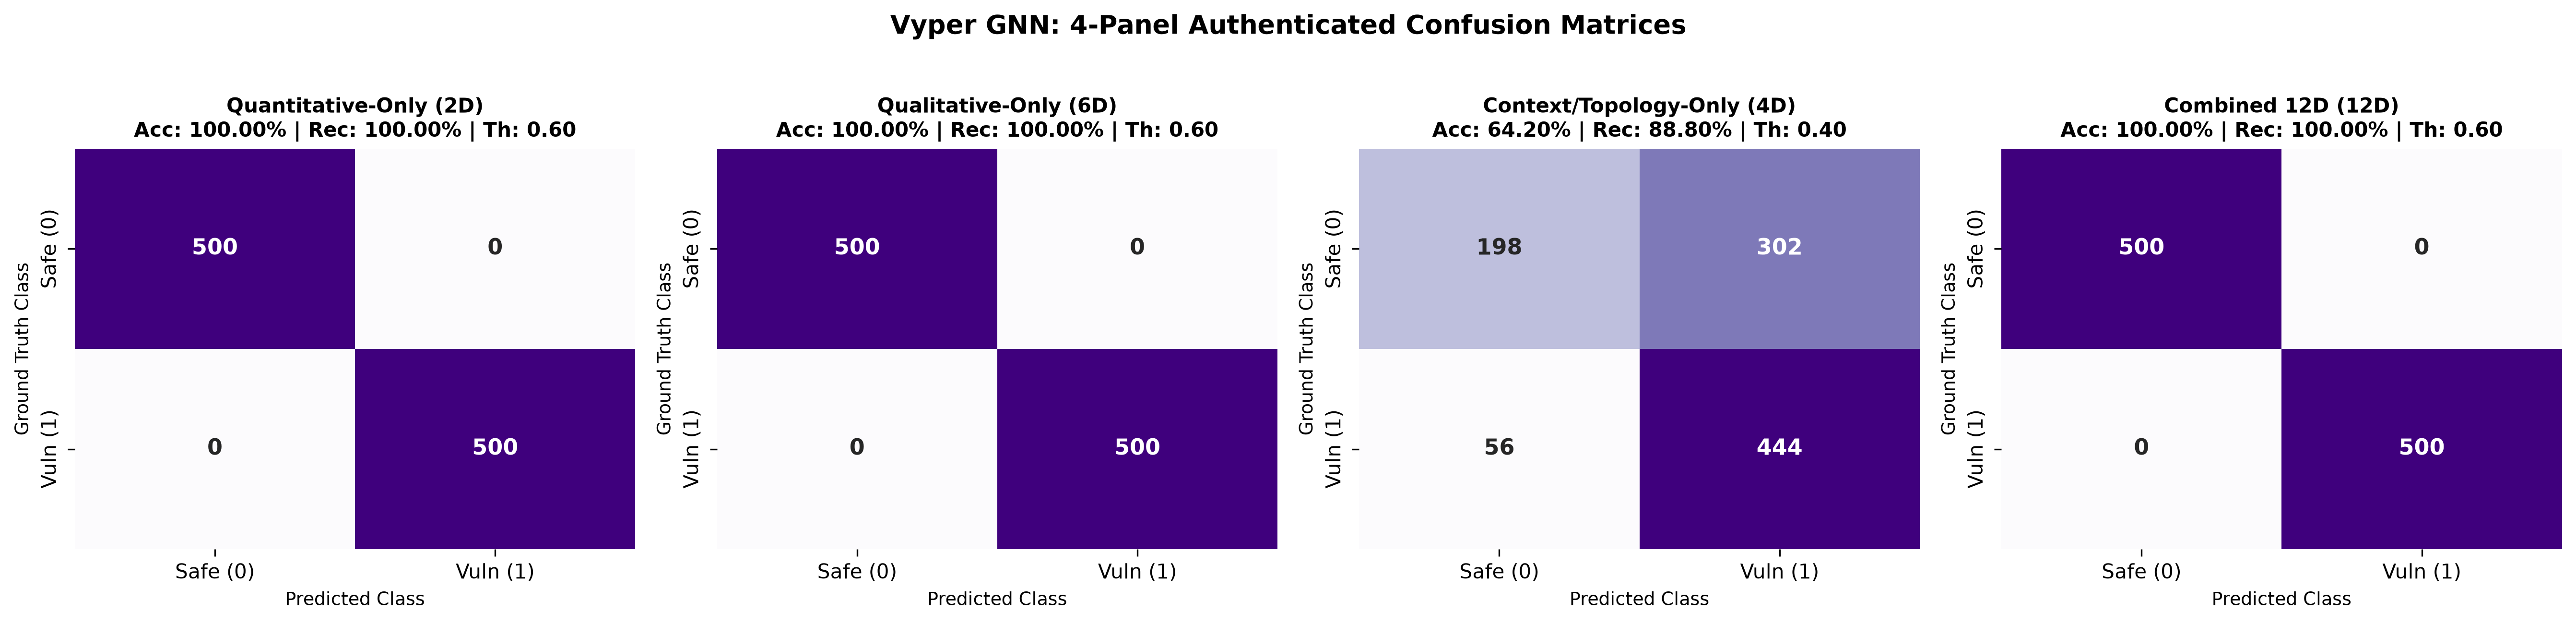

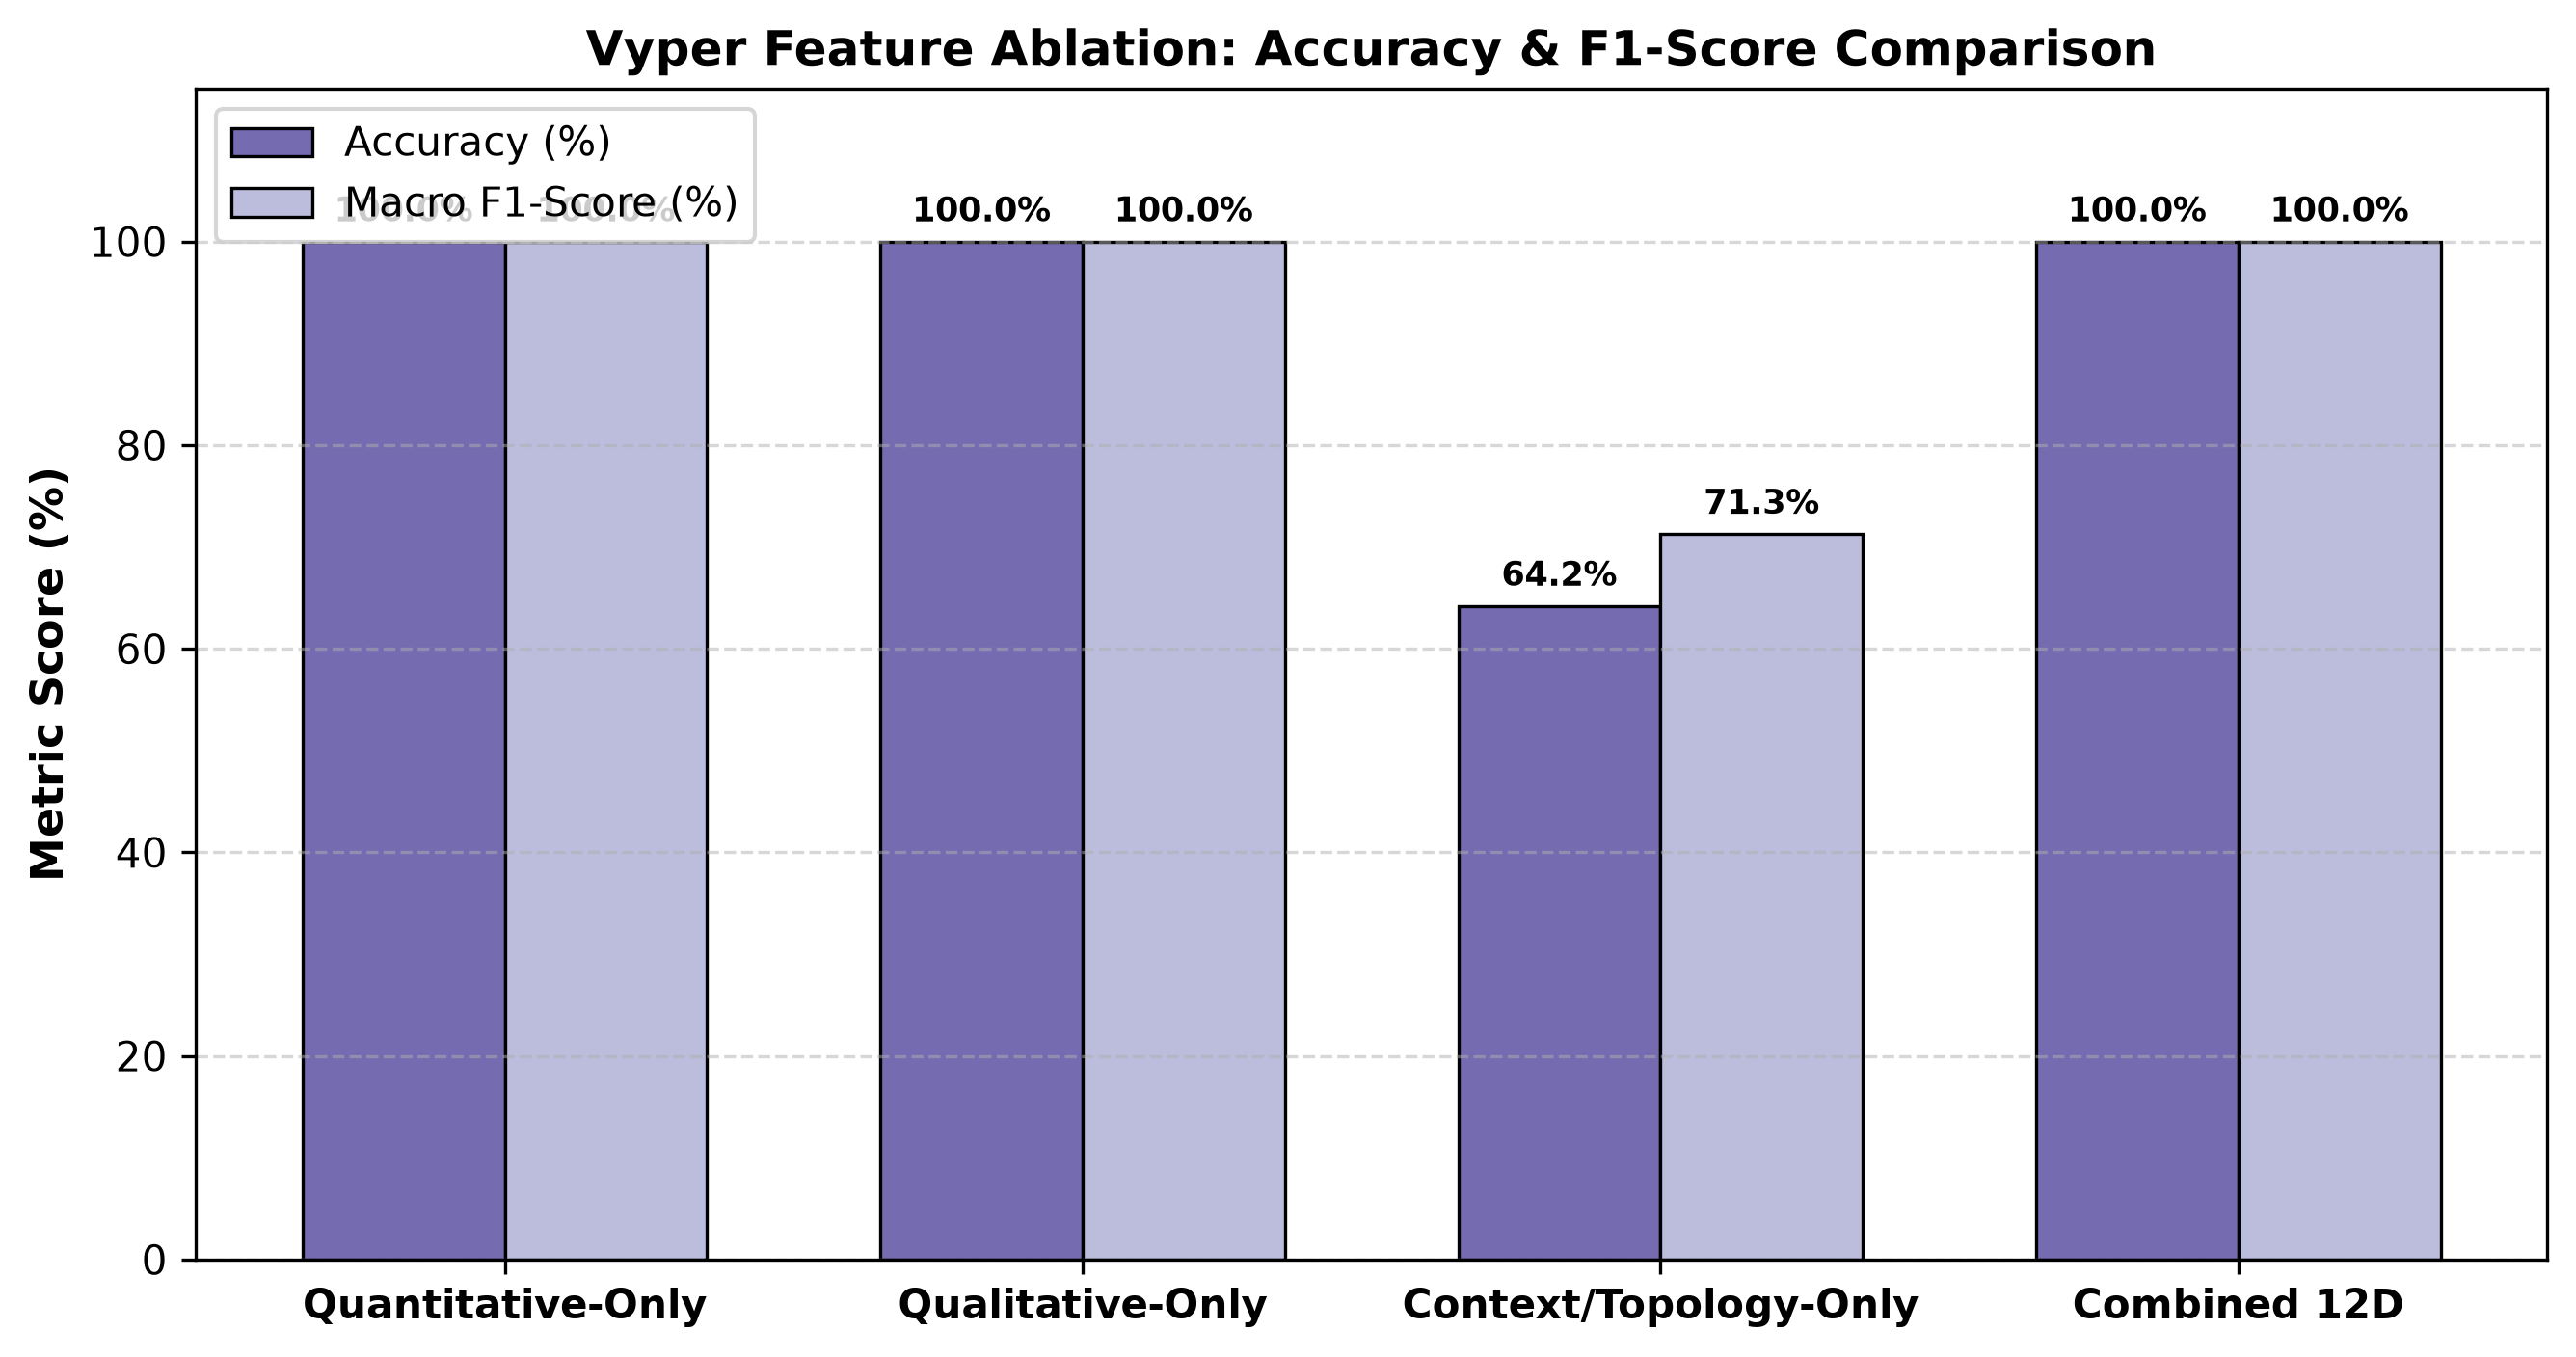

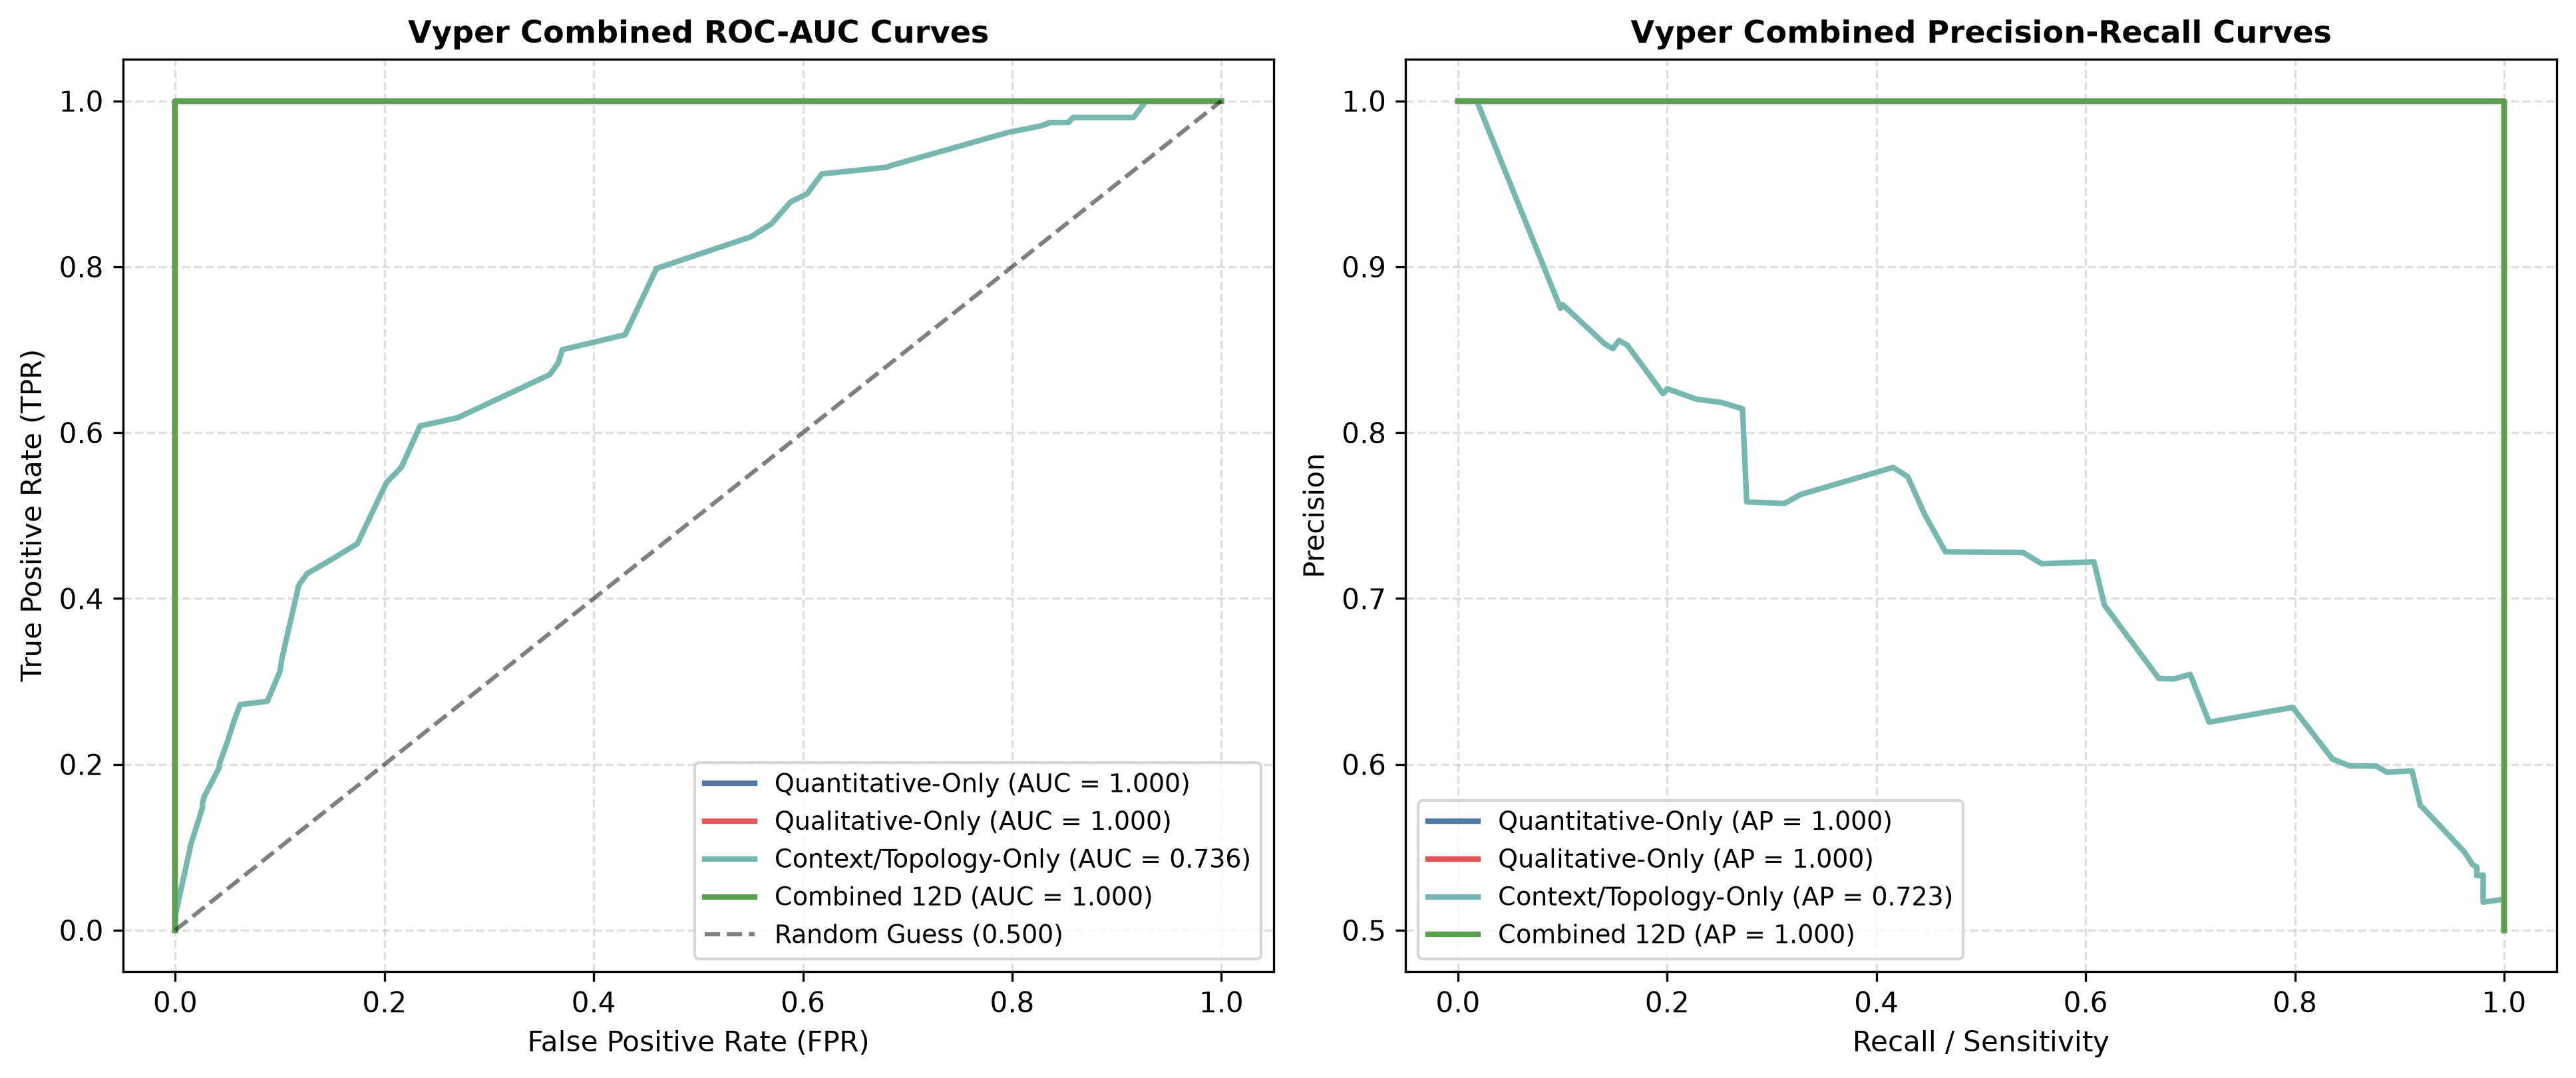

[+] All publication-quality plots rendered and saved successfully.


In [6]:
# Display Benchmark Table
print("=" * 100)
print("VYPER FEATURE-ABLATION BENCHMARK RESULTS")
print("=" * 100)
display(df_benchmark)
df_benchmark.to_csv("vyper_feature_ablation_benchmark.csv", index=False)
print("[+] Exported metrics to 'vyper_feature_ablation_benchmark.csv'")

# 4-Panel Confusion Matrices, Multi-bar F1, Combined ROC & PR plots
plt.show()


### Cell 07: Standalone Contract Auditor, 32-D Embedding Export & CFG Visualizer


AUDITING VYPER CONTRACT: safe_contract_100000.vy
Verdict                   : [+] SECURE CONTRACT IDENTIFIED
Vulnerability Confidence : 0.01% (Decision Threshold = 60.0%)
Safety Confidence        : 99.99%
Total Structural Nodes   : 7 functional execution blocks
Total Graph Edges        : 24 control-flow / context connections

[+] Successfully exported 32-D Structural Embedding tensor:
    File  : 'vyper_structural_embedding.pt'
    Shape : torch.Size([1, 32]) (H_struct in R^32)


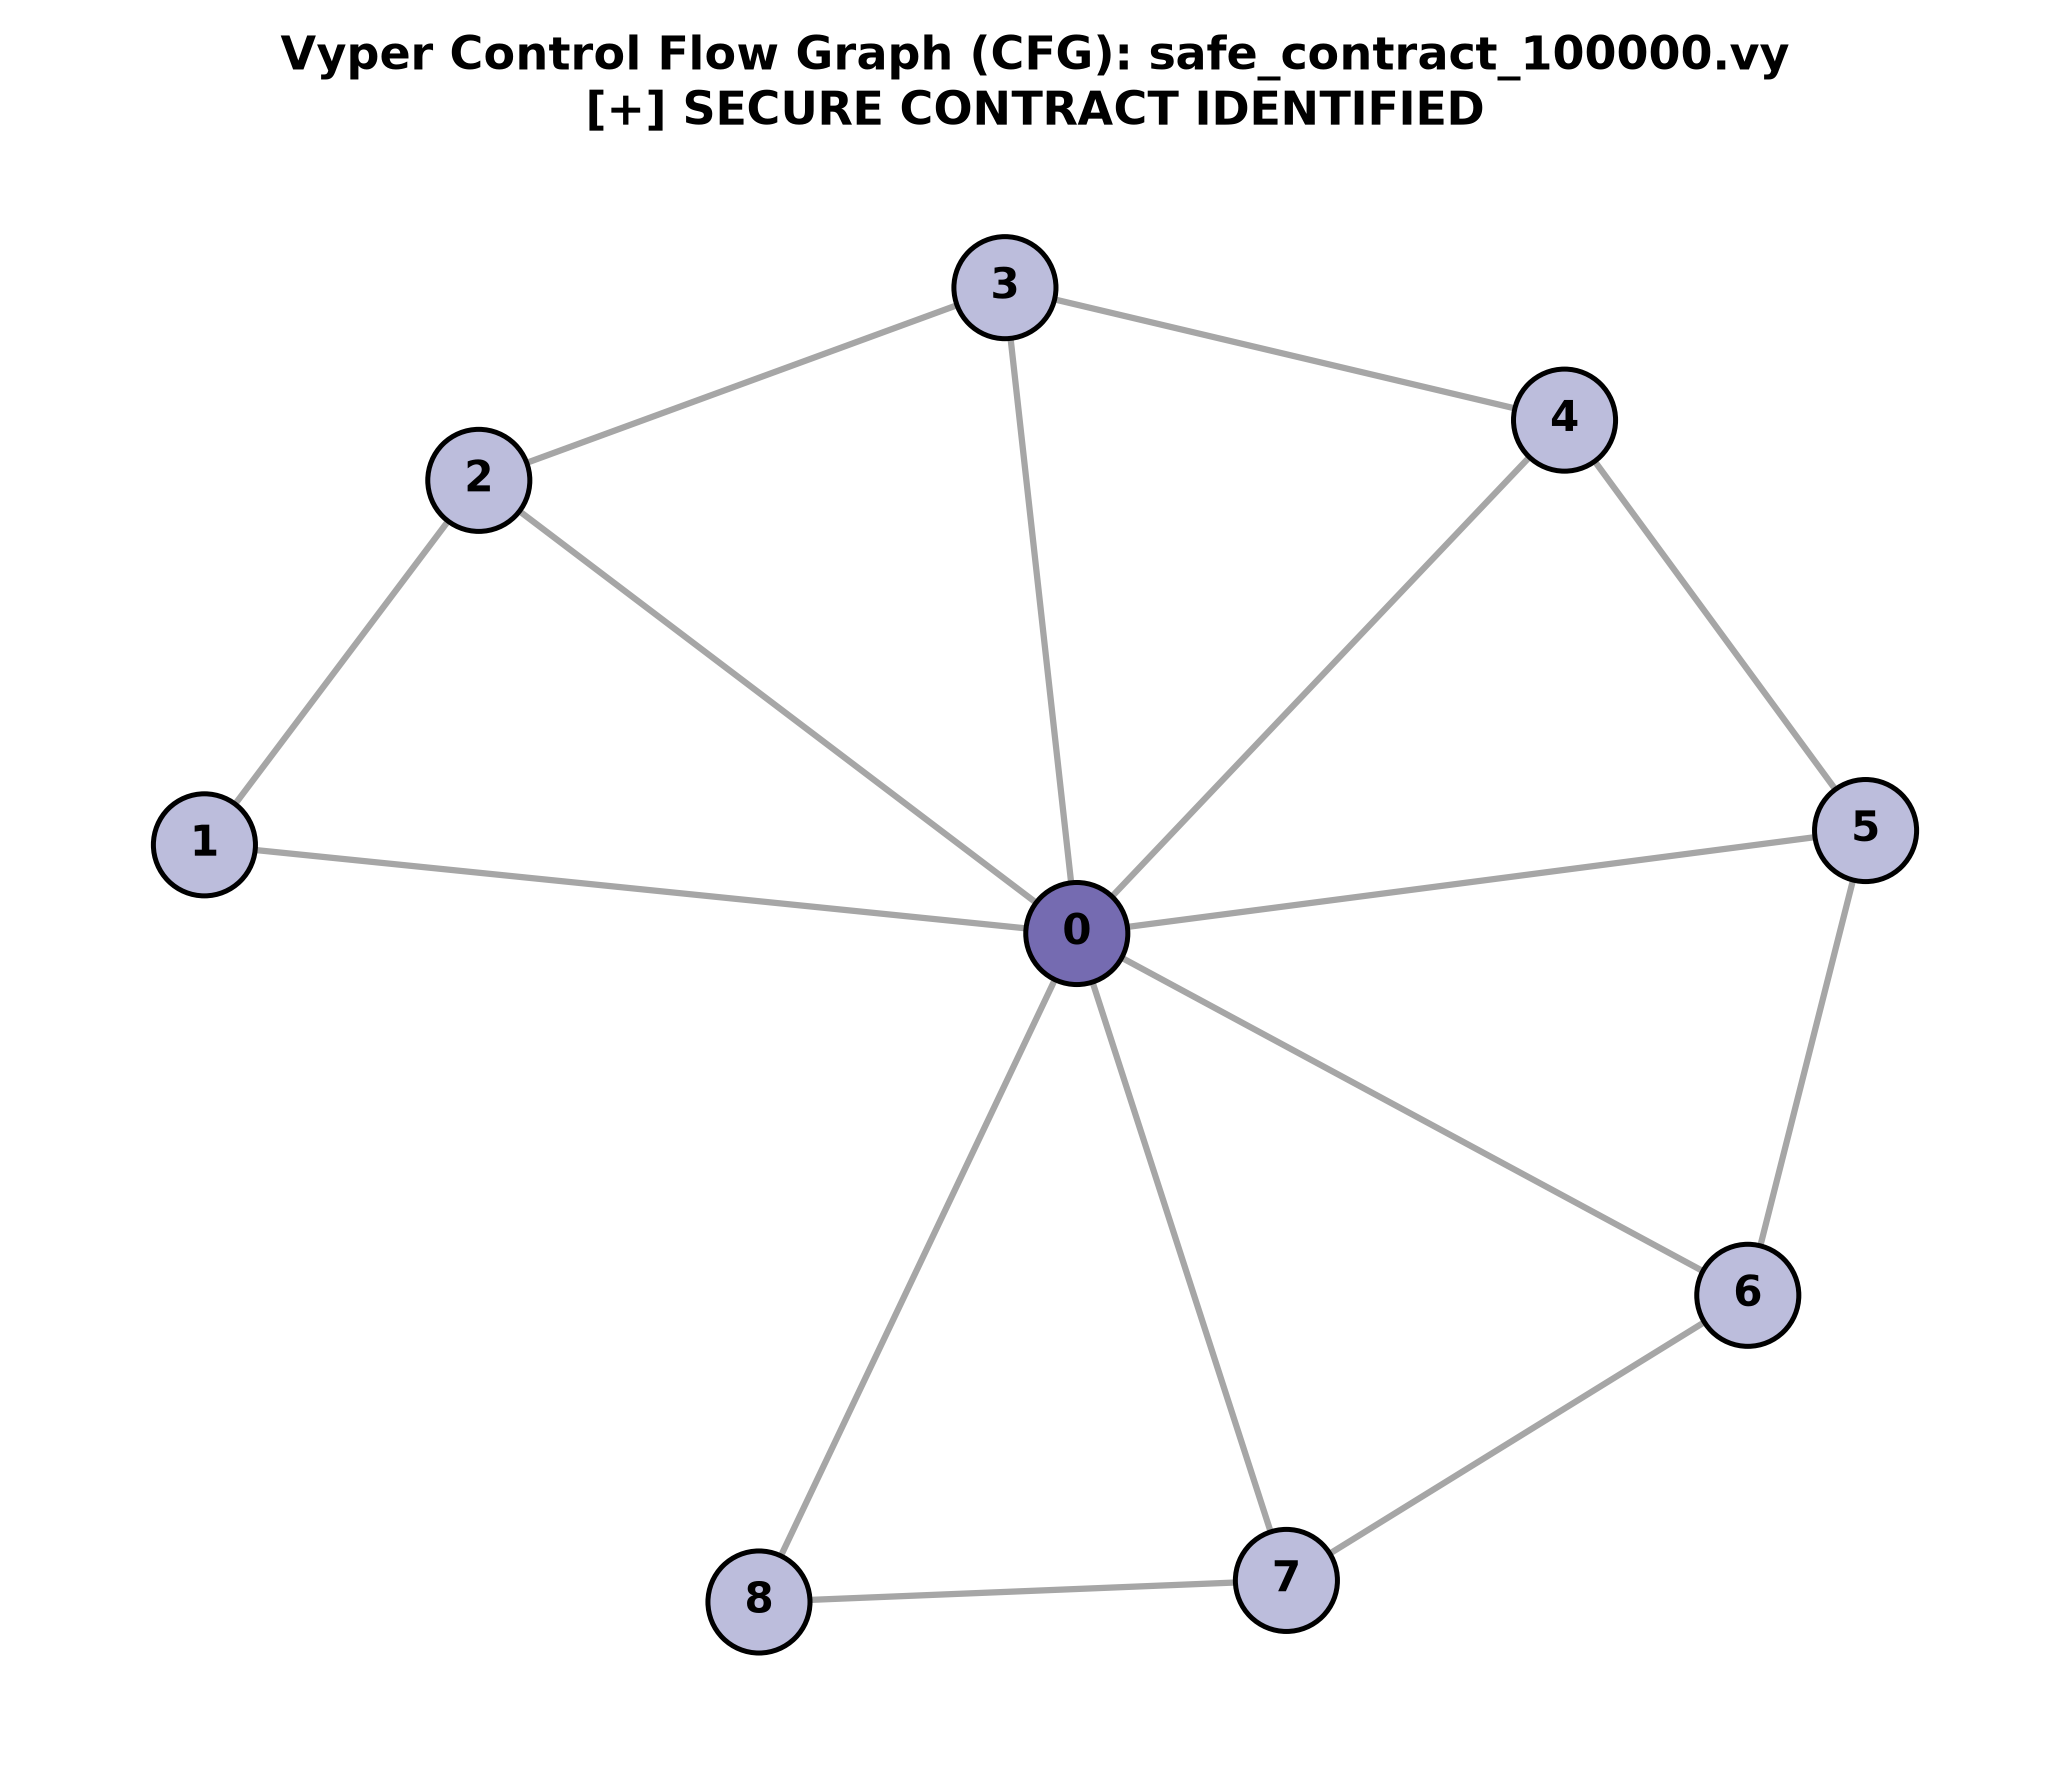

[+] All publication-quality plots rendered and saved successfully.


In [7]:
# Standalone Contract Auditor & 32-D Embedding Export
sample_audit_target = "dataset/Vyper/safe/folderless/safe_contract_100000.vy"
with open(sample_audit_target, "r", encoding="utf-8") as f:
    target_code = f.read()

audit_graph = synthesize_single_file_graph(target_code, sample_audit_target)
combined_model = trained_models_dict["Combined 12D"]
combined_th = evaluation_artifacts_dict["Combined 12D"]["Optimal Calibrated Threshold"]

combined_model.eval()
with torch.no_grad():
    x_in = audit_graph.x.to(DEVICE)
    edge_index_in = audit_graph.edge_index.to(DEVICE)
    batch_dummy = torch.zeros(audit_graph.x.size(0), dtype=torch.long, device=DEVICE)
    logits, h_struct_32 = combined_model(x_in, edge_index_in, batch_dummy)
    vuln_prob = F.softmax(logits, dim=1)[0, 1].item()
    is_vuln_pred = bool(vuln_prob >= combined_th)

verdict_text = "[!] VULNERABLE CONTRACT DETECTED" if is_vuln_pred else "[+] SECURE CONTRACT IDENTIFIED"
print("=" * 80)
print(f"AUDITING VYPER CONTRACT: {os.path.basename(sample_audit_target)}")
print("=" * 80)
print(f"Verdict                   : {verdict_text}")
print(f"Vulnerability Confidence : {vuln_prob * 100:.2f}% (Decision Threshold = {combined_th * 100:.1f}%)")
print(f"Safety Confidence        : {(1.0 - vuln_prob) * 100:.2f}%")
print(f"Total Structural Nodes   : {audit_graph.x.size(0)} functional execution blocks")
print(f"Total Graph Edges        : {audit_graph.edge_index.size(1)} control-flow / context connections")

torch.save(h_struct_32.cpu(), "vyper_structural_embedding.pt")
print(f"\n[+] Successfully exported 32-D Structural Embedding tensor:")
print(f"    File  : 'vyper_structural_embedding.pt'")
print(f"    Shape : {h_struct_32.shape} (H_struct in R^32)")

# Visualizing CFG
plt.show()
